# Customer Segmentation & Sales Prediction using Machine Learning
**Dataset:** UCI *Online Retail II* (UK online gift retailer, 1 Dec 2009 - 9 Dec 2011, ~1.07 million invoice lines)

This notebook covers the nine ML lab experiments on the real dataset and shares its data-preparation code (`backend.py`) with the Streamlit app, so the notebook and the dashboard always use the same features, the same train/test split and compatible models.

| # | Experiment | Where it is applied |
|---|-----------|---------------------|
| 1 | Data preprocessing & EDA | raw transactions -> cleaned transactions -> customer table |
| 2 | Encoding & feature scaling | country group, recency bands, log + standard scaling |
| 3 | Simple linear regression | next-90-day spend from past spend |
| 4 | Logistic regression | will the customer buy again in the next 90 days? |
| 5 | KNN (from scratch) & Gaussian Naive Bayes | same classification task |
| 6 | K-Means | RFM customer segments |
| 7 | Gaussian Mixture Model + PCA | soft segments, compared with K-Means |
| 8 | Ensemble learning | Decision Tree vs Bagging vs Random Forest |
| 9 | Cross-validation & hyper-parameter optimisation | GridSearchCV, RandomizedSearchCV |

## Problem design (decided after inspecting the data)
The raw file is **transaction-level** (one row per product on an invoice) and has **no ready-made target**. We therefore build a **customer-level** table:

* A **snapshot date** (`cutoff`) is placed 90 days before the last transaction (**2011-09-11**).
* **Features** (RFM, basket statistics, returns, country...) use *only* transactions **before** the cutoff.
* **Targets** use *only* the 90 days **after** the cutoff:
  * regression: `FutureSpend` (GBP spent in the next 90 days, 0 if none),
  * classification: `Active` = 1 if the customer purchased again in that window,
  * clustering: unsupervised RFM segmentation (no target used).

Because the targets lie strictly in the future of every feature, there is **no target leakage by construction**. All scaling/imputation/encoding lives inside scikit-learn pipelines fitted on the training split only.

## 0. Setup
Works locally and in Google Colab. In Colab, upload `customer_segmentation_project.zip` when asked (it contains `backend.py`, the dataset and the saved models).

In [1]:
import os, sys, zipfile, pathlib
IN_COLAB = 'google.colab' in sys.modules

def _project_root():
    for p in [pathlib.Path('.')] + [d for d in pathlib.Path('.').iterdir() if d.is_dir()]:
        if (p / 'backend.py').exists():
            return p
    return None

root = _project_root()
if root is None:
    if not IN_COLAB:
        raise FileNotFoundError('backend.py not found - run this notebook from the project folder.')
    from google.colab import files
    print('Upload customer_segmentation_project.zip ...')
    up = files.upload()
    zipfile.ZipFile(next(iter(up))).extractall('.')
    root = _project_root()
os.chdir(root)
sys.path.insert(0, os.getcwd())

DATA_FILE = pathlib.Path('data/online_retail_II.xlsx')
if not DATA_FILE.exists():
    if not IN_COLAB:
        raise FileNotFoundError('Put online_retail_II.xlsx (or .csv) in the data/ folder.')
    from google.colab import files
    os.makedirs('data', exist_ok=True)
    print('Upload your dataset (CSV or Excel) ...')
    up = files.upload(); name = next(iter(up))
    os.replace(name, 'data/' + name); DATA_FILE = pathlib.Path('data/' + name)
print('Working directory:', os.getcwd(), '| dataset:', DATA_FILE)

Working directory: /home/claude/proj | dataset: data/online_retail_II.xlsx


In [2]:
import warnings, time, joblib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display, Markdown
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid'); plt.rcParams['figure.dpi'] = 100
pd.set_option('display.max_columns', 40); pd.set_option('display.width', 170)

import backend as B
from sklearn.base import clone
from sklearn.cluster import KMeans
from sklearn.model_selection import (train_test_split, StratifiedKFold, KFold, cross_val_score, cross_validate,
                                     GridSearchCV, RandomizedSearchCV)
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, OrdinalEncoder, MinMaxScaler, StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             mean_absolute_error, mean_squared_error, r2_score, silhouette_score,
                             adjusted_rand_score, normalized_mutual_info_score)
import sklearn; print('scikit-learn', sklearn.__version__, '| pandas', pd.__version__)

scikit-learn 1.9.1 | pandas 3.0.5


# Experiment 1 - Data Preprocessing & Exploratory Data Analysis
**Aim:** understand the raw data, quantify missing values and duplicates, clean it, and engineer a customer-level table.

In [3]:
t0 = time.time()
raw = B.load_raw_cached(DATA_FILE)           # both Excel sheets stacked (cached as parquet after first run)
print(f'Loaded {raw.shape[0]:,} rows x {raw.shape[1]} columns in {time.time()-t0:.0f}s')
display(raw.head())
raw.info()

Loaded 1,067,371 rows x 8 columns in 55s


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,CustomerID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[us]
 5   Price        1067371 non-null  float64       
 6   CustomerID   824364 non-null   float64       
 7   Country      1067371 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 78.8+ MB


### 1.1 Missing values, duplicates and invalid values

,Missing,Missing %,Unique
Invoice,0,0.00,53628
StockCode,0,0.00,5305
Description,4382,0.41,5698
Quantity,0,0.00,1057
InvoiceDate,0,0.00,47635
Price,0,0.00,2807
CustomerID,243007,22.77,5942
Country,0,0.00,43


Exact duplicate rows      : 34,335
Quantity <= 0 (returns)   : 22,950
Price <= 0                : 6,207


Cancellation invoices (C*): 19,494


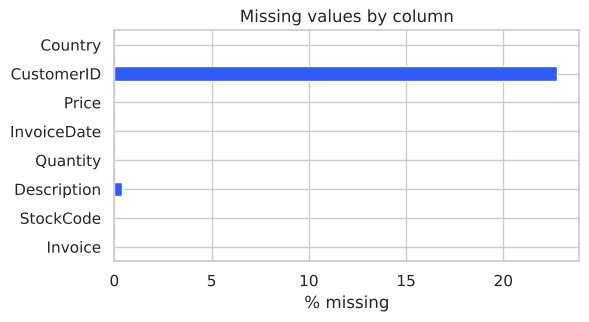

In [4]:
miss = pd.DataFrame({'Missing': raw.isna().sum(), 'Missing %': (raw.isna().mean()*100).round(2), 'Unique': raw.nunique()})
display(miss)
print('Exact duplicate rows      :', f'{raw.duplicated().sum():,}')
print('Quantity <= 0 (returns)   :', f'{(raw.Quantity <= 0).sum():,}')
print('Price <= 0                :', f'{(raw.Price <= 0).sum():,}')
print('Cancellation invoices (C*):', f'{raw.Invoice.astype(str).str.startswith("C").sum():,}')
fig, ax = plt.subplots(figsize=(6, 3))
miss['Missing %'].plot.barh(ax=ax, color='#2E5BFF'); ax.set_xlabel('% missing'); ax.set_title('Missing values by column')
plt.show()

**Findings.** `Customer ID` is missing on ~22% of rows (guest checkouts) and `Description` on ~0.4%. A customer-level model cannot use rows without a customer, so they are dropped (imputing an ID would be meaningless). The two Excel sheets overlap in December 2010, which is why ~34k exact duplicates exist - these are removed. Negative quantities are cancellations/returns (invoice numbers starting with `C`); they are kept separately to compute a **return rate** feature. Non-merchandise lines (postage, bank charges, manual adjustments, gift vouchers) are excluded from sales.

In [5]:
sales, returns, log = B.clean_transactions(raw)
display(pd.Series(log, name='rows').to_frame())
print(f'Valid sales lines: {len(sales):,} | customers: {sales.CustomerID.nunique():,} | countries: {sales.Country.nunique()}')
display(sales[['Quantity', 'Price', 'Revenue']].describe().T)

,rows
raw_rows,1067371
duplicate_rows_removed,34335
missing_customer_id_removed,235151
non_product_lines_removed,3662
cancellation_lines,17586
invalid_qty_or_price_removed,60
valid_sales_lines,776577


Valid sales lines: 776,577 | customers: 5,852 | countries: 41


,count,mean,std,min,25%,50%,75%,max
Quantity,776577.0,13.519243,146.096695,1.00,2.00,6.00,12.00,80995.0
Price,776577.0,2.934561,4.293610,0.03,1.25,1.95,3.75,649.5
Revenue,776577.0,21.979234,225.932983,0.06,4.95,12.45,19.80,168469.6


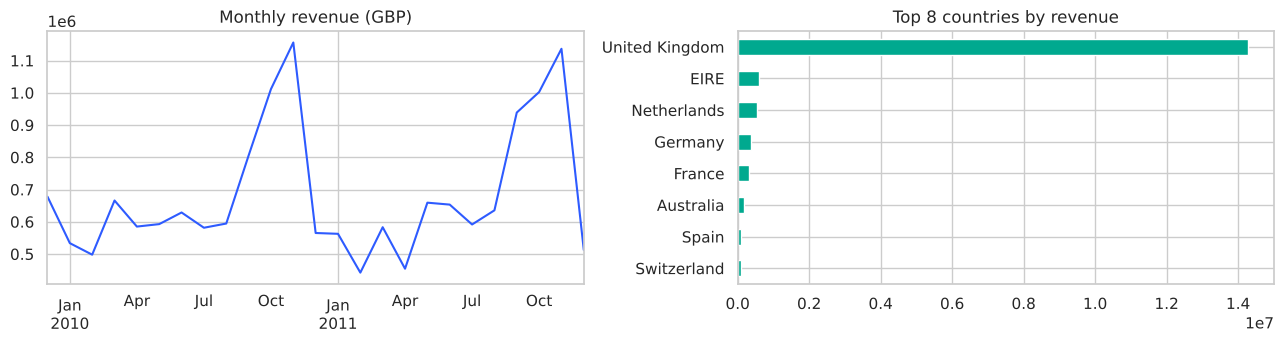

In [6]:
monthly = sales.set_index('InvoiceDate').resample('MS')['Revenue'].sum()
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
monthly.plot(ax=ax[0], color='#2E5BFF'); ax[0].set_title('Monthly revenue (GBP)'); ax[0].set_xlabel('')
sales.groupby('Country')['Revenue'].sum().nlargest(8).sort_values().plot.barh(ax=ax[1], color='#00A98F')
ax[1].set_title('Top 8 countries by revenue'); ax[1].set_ylabel('')
plt.tight_layout(); plt.show()

### 1.2 Feature engineering: transactions -> one row per customer
Using `backend.build_customer_table` (snapshot = 2011-09-11, horizon = 90 days):

| Feature | Meaning |
|---|---|
| Recency / Frequency / Monetary | days since last order / number of orders / total spend (RFM) |
| AvgOrderValue, TotalQuantity, UniqueProducts, AvgLinesPerOrder | basket characteristics |
| TenureDays, AvgDaysBetweenOrders | relationship length and purchase rhythm (undefined for one-order customers -> missing) |
| Orders_Last90, Spend_Last90 | recent activity before the snapshot |
| ReturnRate | share of spend that was returned |
| CountryGroup | UK, EIRE, Germany, France, Other |
| **FutureSpend, Active** | targets: spend / purchase in the *following* 90 days |

In [7]:
cutoff = B.default_cutoff(sales)
cust = B.build_customer_table(sales, returns, cutoff)
print('Snapshot date:', cutoff.date(), '| customers:', len(cust))
display(cust.head())
print(f"Customers who bought again within {B.HORIZON_DAYS} days: {cust.Active.mean():.1%}")

Snapshot date: 2011-09-11 | customers: 5256


,CustomerID,Recency,Frequency,Monetary,AvgOrderValue,TotalQuantity,UniqueProducts,AvgLinesPerOrder,TenureDays,AvgDaysBetweenOrders,Orders_Last90,Spend_Last90,ReturnRate,CountryGroup,Country,FutureSpend,Active
0,12346,235,3,77352.96,25784.320,74239,25,8.333333,557,160.5,0,0.00,0.997811,United Kingdom,United Kingdom,0.00,0
1,12347,39,6,3402.39,567.065,2099,107,27.333333,314,54.8,1,584.91,0.000000,Other,Iceland,1519.14,1
2,12348,158,4,1388.40,347.100,2488,24,11.000000,348,63.0,0,0.00,0.000000,Other,Finland,270.00,1
3,12349,317,2,2221.14,1110.570,991,89,50.000000,499,181.0,0,0.00,0.010873,Other,Italy,1457.55,1
4,12350,220,1,294.40,294.400,196,16,16.000000,220,NaN,0,0.00,0.000000,Other,Norway,0.00,0


Customers who bought again within 90 days: 43.6%


### 1.3 Missing-value analysis and mean / median imputation on the customer table

AvgDaysBetweenOrders    1575
dtype: int64

AvgDaysBetweenOrders: 1575 missing (30.0%) - customers with a single order have no gap.
mean = 90.4, median = 67.4, skewness = 2.12


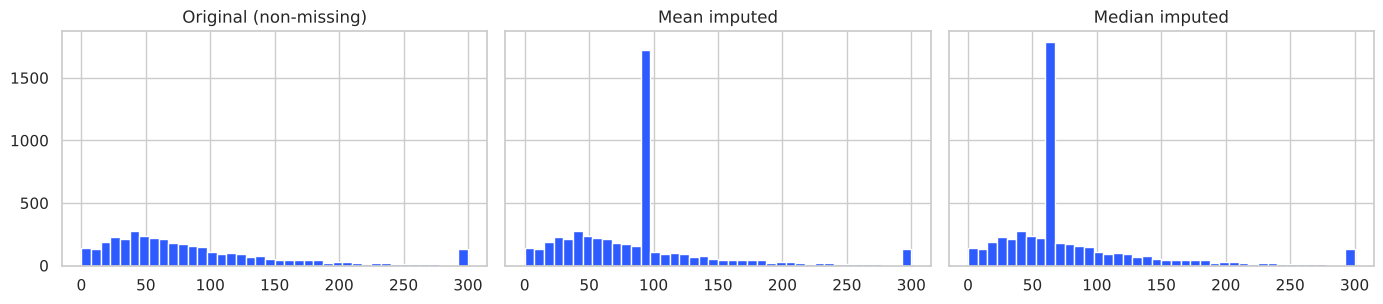

In [8]:
print(cust[B.FEATURES].isna().sum()[lambda s: s > 0])
col = 'AvgDaysBetweenOrders'
s = cust[col]
print(f'\n{col}: {s.isna().sum()} missing ({s.isna().mean():.1%}) - customers with a single order have no gap.')
print(f'mean = {s.mean():.1f}, median = {s.median():.1f}, skewness = {s.skew():.2f}')
fig, ax = plt.subplots(1, 3, figsize=(14, 3.2), sharey=True)
for a, (nm, v) in zip(ax, [('Original (non-missing)', s.dropna()), ('Mean imputed', s.fillna(s.mean())), ('Median imputed', s.fillna(s.median()))]):
    a.hist(v.clip(upper=300), bins=40, color='#2E5BFF'); a.set_title(nm)
plt.tight_layout(); plt.show()

The distribution is strongly right-skewed (skewness > 1), so the **mean** is pulled upward by a few slow buyers and would distort the imputed values. We use the **median** (`SimpleImputer(strategy='median')`) inside the pipelines. Imputing inside the pipeline also means the median is learned from the training split only.

### 1.4 Distributions, outliers and correlations

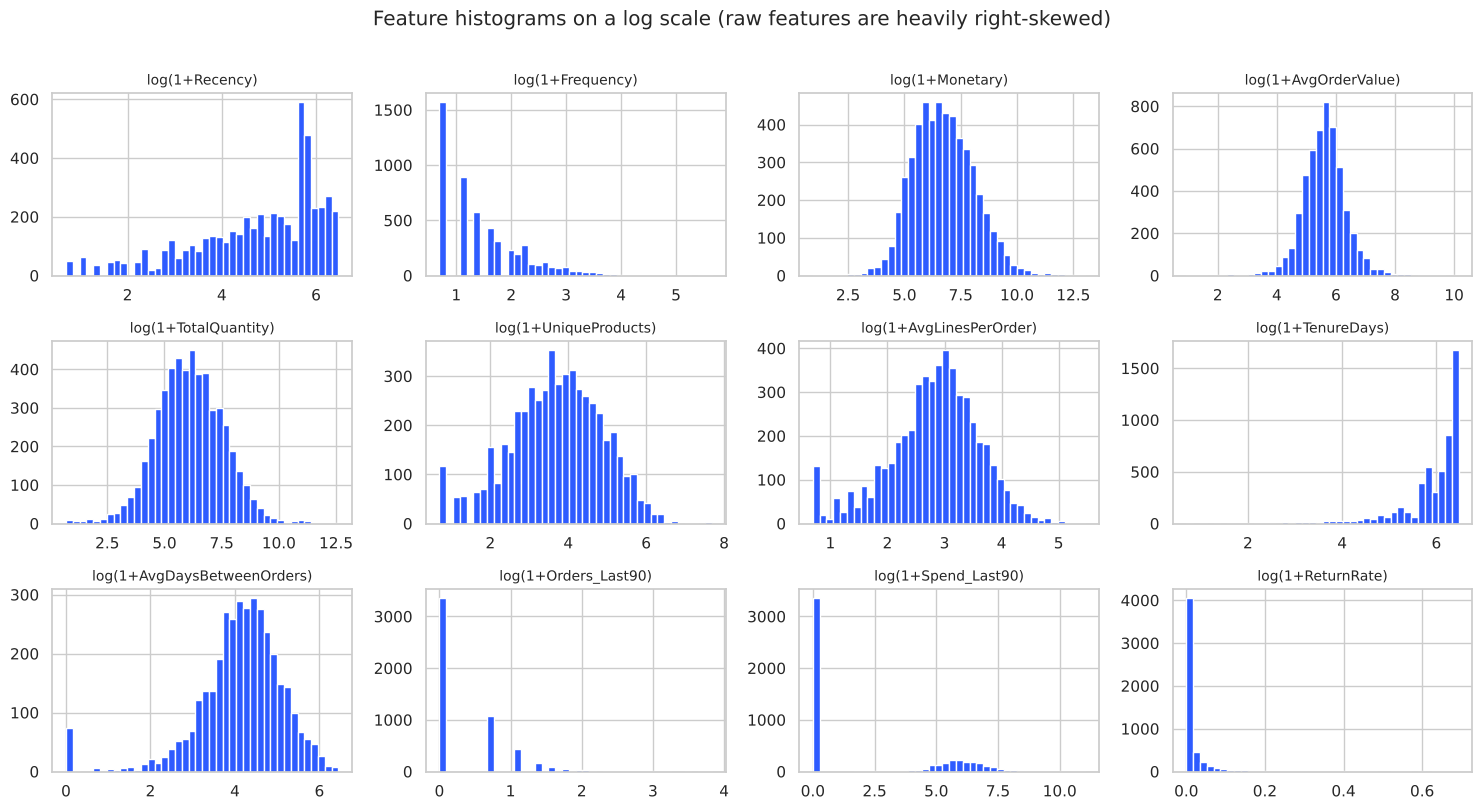

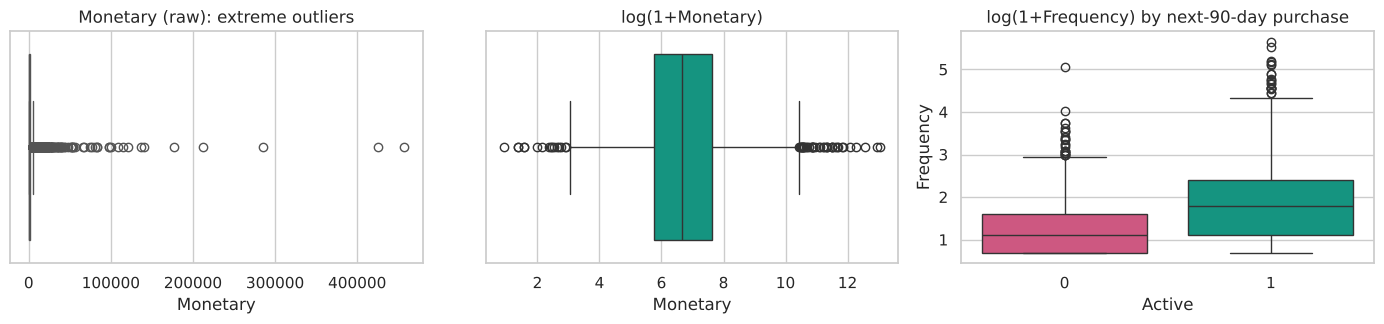

IQR rule flags 10.5% of customers as high outliers in Monetary.


In [9]:
fig, axes = plt.subplots(3, 4, figsize=(15, 8))
for a, c in zip(axes.ravel(), B.NUM_FEATURES):
    a.hist(np.log1p(cust[c].dropna()), bins=40, color='#2E5BFF'); a.set_title(f'log(1+{c})', fontsize=10)
plt.suptitle('Feature histograms on a log scale (raw features are heavily right-skewed)', y=1.01); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(14, 3.4))
sns.boxplot(x=cust.Monetary, ax=ax[0], color='#F5A623'); ax[0].set_title('Monetary (raw): extreme outliers')
sns.boxplot(x=np.log1p(cust.Monetary), ax=ax[1], color='#00A98F'); ax[1].set_title('log(1+Monetary)')
sns.boxplot(data=cust, x='Active', y=np.log1p(cust.Frequency), ax=ax[2], palette=['#E0457B', '#00A98F']); ax[2].set_title('log(1+Frequency) by next-90-day purchase')
plt.tight_layout(); plt.show()
q1, q3 = cust.Monetary.quantile([.25, .75]); iqr = q3 - q1
print(f'IQR rule flags {(cust.Monetary > q3 + 1.5*iqr).mean():.1%} of customers as high outliers in Monetary.')

Outliers here are **genuine wholesale customers**, not errors, and they generate most of the revenue. Deleting them would remove the very customers we care about, so they are **kept** and their influence is tamed with a `log(1+x)` transform.

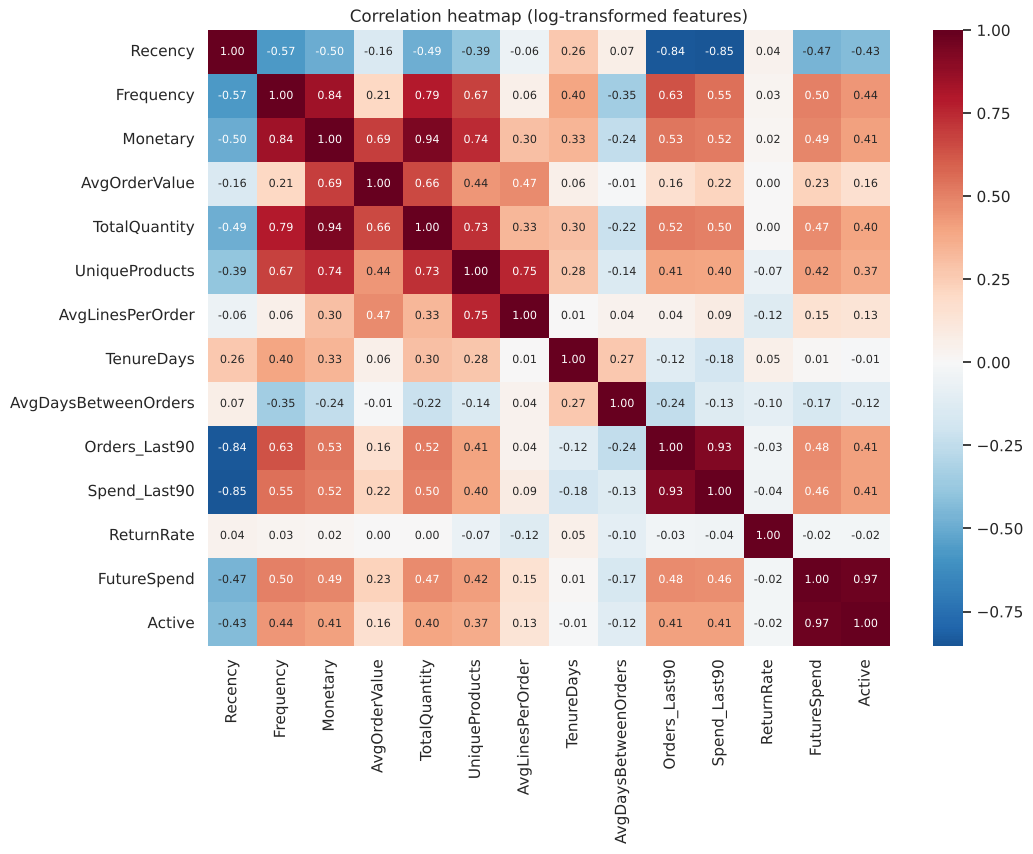

In [10]:
corr_cols = B.NUM_FEATURES + ['FutureSpend', 'Active']
plt.figure(figsize=(11, 8))
sns.heatmap(np.log1p(cust[B.NUM_FEATURES + ['FutureSpend']]).assign(Active=cust.Active)[corr_cols].corr(), annot=True, fmt='.2f',
            cmap='RdBu_r', center=0, annot_kws={'size': 8}); plt.title('Correlation heatmap (log-transformed features)')
plt.show()

**Observations.** Monetary, Frequency, TotalQuantity and UniqueProducts are strongly inter-correlated (big buyers buy often and widely); `Recency` is negatively related to both targets (recent customers come back). The collinearity motivates regularised/tree models and is the reason a single feature (Monetary) is a good *simple* regression predictor.

# Experiment 2 - Encoding & Feature Scaling
First the **train/test split** (80/20, stratified on the classification target, `random_state=42`). This is the same split used by `backend.py`, so notebook and app metrics are directly comparable. All encoders/scalers below are **fitted on the training set only**.

In [11]:
X = cust[B.FEATURES]; y_reg = cust['FutureSpend']; y_clf = cust['Active']
X_train, X_test, ytr_r, yte_r, ytr_c, yte_c = train_test_split(X, y_reg, y_clf, test_size=0.2,
                                                                random_state=B.RANDOM_STATE, stratify=y_clf)
print('train', X_train.shape, 'test', X_test.shape, '| positive rate train/test:', round(ytr_c.mean(), 3), round(yte_c.mean(), 3))

train (4204, 13) test (1052, 13) | positive rate train/test: 0.436 0.435


### 2.1 Label, one-hot and ordinal encoding

In [12]:
# Label encoding: integer code per category (no order implied by the data - suitable for tree models only)
le = LabelEncoder().fit(X_train.CountryGroup)
print('Label encoding:', dict(zip(le.classes_, le.transform(le.classes_))))

# One-hot encoding: one binary column per category (appropriate for linear / distance-based models)
ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False).fit(X_train[['CountryGroup']])
oh = pd.DataFrame(ohe.transform(X_test[['CountryGroup']]), columns=ohe.get_feature_names_out(), index=X_test.index)
display(pd.concat([X_test[['CountryGroup']], oh], axis=1).head())

# Ordinal encoding: Recency has a natural order, so we bin it into ordered bands
bands = ['0-30d', '31-90d', '91-180d', '181-365d', '365d+']
def recency_band(s): return pd.cut(s, [-1, 30, 90, 180, 365, np.inf], labels=bands)
rb_train = recency_band(X_train.Recency).astype(str).to_frame('RecencyBand')
oe = OrdinalEncoder(categories=[bands]).fit(rb_train)
demo = rb_train.head(8).copy(); demo['RecencyBand_code'] = oe.transform(demo).ravel()
display(demo)
tab = pd.DataFrame({'band': rb_train.RecencyBand, 'active': ytr_c}).groupby('band').active.agg(['size', 'mean']).reindex(bands)
display(tab.rename(columns={'size': 'customers', 'mean': 'repeat rate'}).style.format({'repeat rate': '{:.1%}'}))

Label encoding: {'EIRE': np.int64(0), 'France': np.int64(1), 'Germany': np.int64(2), 'Other': np.int64(3), 'United Kingdom': np.int64(4)}


,CountryGroup,CountryGroup_EIRE,CountryGroup_France,CountryGroup_Germany,CountryGroup_Other,CountryGroup_United Kingdom
34,Other,0.0,0.0,0.0,1.0,0.0
2982,United Kingdom,0.0,0.0,0.0,0.0,1.0
1974,United Kingdom,0.0,0.0,0.0,0.0,1.0
3585,United Kingdom,0.0,0.0,0.0,0.0,1.0
5030,United Kingdom,0.0,0.0,0.0,0.0,1.0


,RecencyBand,RecencyBand_code
209,31-90d,1.0
2472,0-30d,0.0
1879,181-365d,3.0
1464,365d+,4.0
5247,365d+,4.0
3636,365d+,4.0
4387,181-365d,3.0
4593,181-365d,3.0


,customers,repeat rate
band,,
0-30d,760,73.9%
31-90d,773,63.5%
91-180d,703,46.1%
181-365d,1203,30.8%
365d+,765,11.0%


Choice in the models: `CountryGroup` is one-hot encoded (nominal); `Recency` is kept numeric (the continuous value carries more information than the ordinal band, which is shown here only to demonstrate ordinal encoding and the strong monotone relationship with repeat purchase).

### 2.2 Feature scaling: Min-Max vs Standard vs log + Standard

,mean,std,min,max
raw,2691.032,13096.046,2.900,456780.490
MinMax,0.006,0.029,0.000,1.000
Standard,0.000,1.000,-0.205,34.678
log1p + Standard,-0.000,1.000,-3.920,4.594


Skewness: {'raw': 23.26, 'MinMax': 23.26, 'Standard': 23.26, 'log1p + Standard': 0.29}


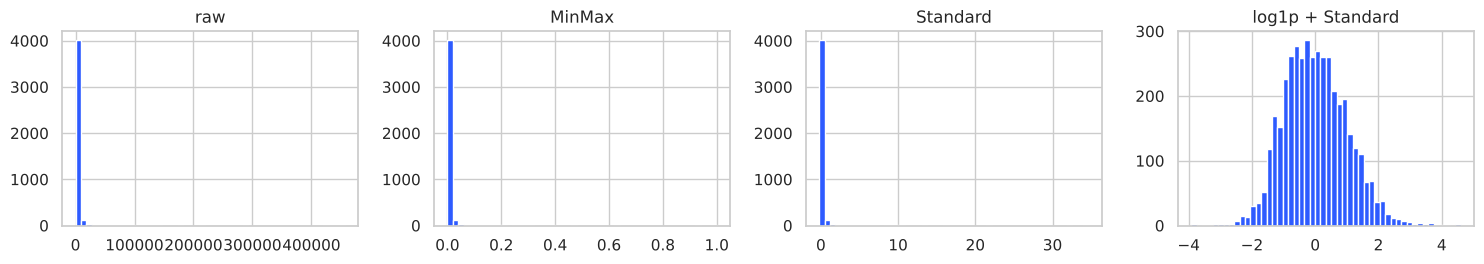

In [13]:
m = X_train[['Monetary']]
mm = MinMaxScaler().fit(m); st = StandardScaler().fit(m); lg = StandardScaler().fit(np.log1p(m))
sc = pd.DataFrame({'raw': m.Monetary, 'MinMax': mm.transform(m).ravel(), 'Standard': st.transform(m).ravel(),
                   'log1p + Standard': lg.transform(np.log1p(m)).ravel()})
display(sc.describe().T[['mean', 'std', 'min', 'max']].round(3))
print('Skewness:', sc.skew().round(2).to_dict())
fig, ax = plt.subplots(1, 4, figsize=(15, 2.8))
for a, c in zip(ax, sc.columns):
    a.hist(sc[c], bins=50, color='#2E5BFF'); a.set_title(c)
plt.tight_layout(); plt.show()

Min-Max and Standard scaling only change the *range*; the extreme right skew remains and a few wholesale customers still dominate distances. `log1p` followed by standardisation fixes both. That is the transformation used for linear, KNN, Naive Bayes and clustering models (`backend.make_preprocessor`). Tree-based models are scale-invariant, so they only get median imputation.

In [14]:
pre = B.make_preprocessor()
Z_train = pre.fit_transform(X_train); Z_test = pre.transform(X_test)
print('Preprocessed matrix:', Z_train.shape, '| any NaN left:', np.isnan(Z_train).any())
print(list(pre.get_feature_names_out()))

Preprocessed matrix: (4204, 17) | any NaN left: False
['num__Recency', 'num__Frequency', 'num__Monetary', 'num__AvgOrderValue', 'num__TotalQuantity', 'num__UniqueProducts', 'num__AvgLinesPerOrder', 'num__TenureDays', 'num__AvgDaysBetweenOrders', 'num__Orders_Last90', 'num__Spend_Last90', 'num__ReturnRate', 'cat__CountryGroup_EIRE', 'cat__CountryGroup_France', 'cat__CountryGroup_Germany', 'cat__CountryGroup_Other', 'cat__CountryGroup_United Kingdom']


# Experiment 3 - Simple Linear Regression
**Task:** predict `FutureSpend` (spend in the next 90 days). Spend is extremely right-skewed (and 56% of customers spend 0), so we model **log(1 + spend)** and convert predictions back to GBP.

**Simple linear regression** uses one predictor: `x = log(1 + Monetary)` (past spend), `y = log(1 + FutureSpend)`.
Model: $\hat y = w x + b$. Cost function (half mean squared error): $J(w,b) = \frac{1}{2n}\sum (\hat y_i - y_i)^2$.
Least-squares solution: $w = \frac{\sum (x_i-\bar x)(y_i-\bar y)}{\sum (x_i-\bar x)^2},\; b=\bar y - w\bar x$.

Least squares: w = 1.1437, b = -4.9518, J(w,b) = 3.9407
sklearn check: w = 1.1437, b = -4.9518  (identical)


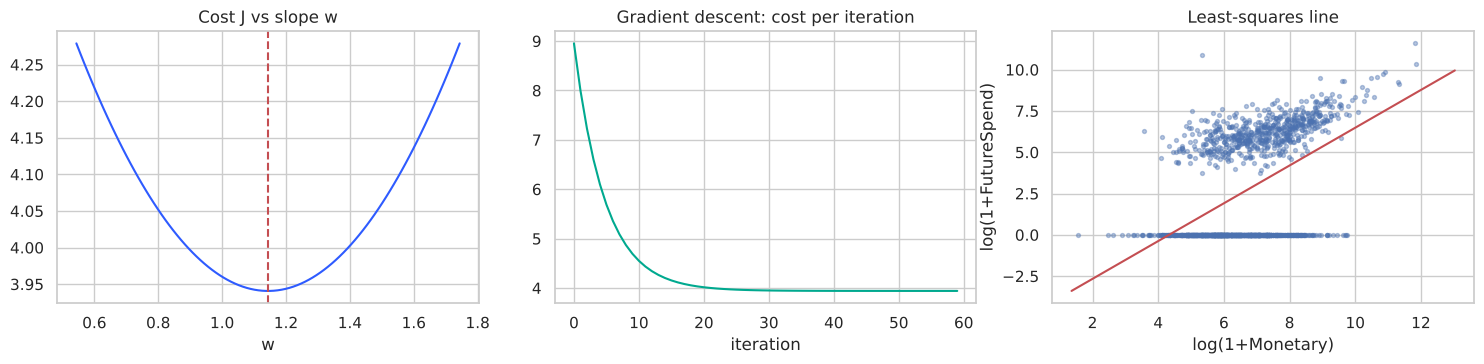

In [15]:
x = np.log1p(X_train.Monetary.values); y = np.log1p(ytr_r.values)
w = ((x - x.mean()) * (y - y.mean())).sum() / ((x - x.mean())**2).sum()
b = y.mean() - w * x.mean()
J = lambda w_, b_: ((w_ * x + b_ - y)**2).mean() / 2
print(f'Least squares: w = {w:.4f}, b = {b:.4f}, J(w,b) = {J(w, b):.4f}')

from sklearn.linear_model import LinearRegression
sk = LinearRegression().fit(x.reshape(-1, 1), y)
print(f'sklearn check: w = {sk.coef_[0]:.4f}, b = {sk.intercept_:.4f}  (identical)')

# cost function: J along w (with b at its optimum for each w) and gradient-descent convergence
ws = np.linspace(w - 0.6, w + 0.6, 100)
Jw = [J(wi, y.mean() - wi * x.mean()) for wi in ws]
xs = (x - x.mean()) / x.std(); wg, bg, lr, hist = 0.0, 0.0, 0.1, []
for _ in range(60):
    err = wg * xs + bg - y; hist.append((err**2).mean() / 2)
    wg -= lr * (err * xs).mean(); bg -= lr * err.mean()
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].plot(ws, Jw, color='#2E5BFF'); ax[0].axvline(w, color='r', ls='--'); ax[0].set_title('Cost J vs slope w'); ax[0].set_xlabel('w')
ax[1].plot(hist, color='#00A98F'); ax[1].set_title('Gradient descent: cost per iteration'); ax[1].set_xlabel('iteration')
idx = np.random.RandomState(0).choice(len(x), 1500, replace=False)
ax[2].scatter(x[idx], y[idx], s=8, alpha=.4); xx = np.linspace(x.min(), x.max(), 50); ax[2].plot(xx, w * xx + b, 'r')
ax[2].set_xlabel('log(1+Monetary)'); ax[2].set_ylabel('log(1+FutureSpend)'); ax[2].set_title('Least-squares line')
plt.tight_layout(); plt.show()

,MAE (GBP),MSE,RMSE (GBP),R2 (GBP),R2 (log scale)
Baseline (geometric mean),454.605,2732421.476,1653.004,-0.076,-0.000
Simple linear (manual),418.700,2170184.728,1473.155,0.146,0.261


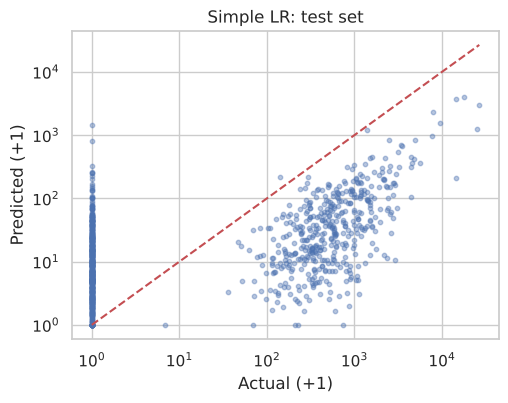

In [16]:
def reg_report(y_true, pred_gbp, name):
    return pd.Series({'MAE (GBP)': mean_absolute_error(y_true, pred_gbp), 'MSE': mean_squared_error(y_true, pred_gbp),
                      'RMSE (GBP)': np.sqrt(mean_squared_error(y_true, pred_gbp)), 'R2 (GBP)': r2_score(y_true, pred_gbp),
                      'R2 (log scale)': r2_score(np.log1p(y_true), np.log1p(pred_gbp))}, name=name)

pred_log = w * np.log1p(X_test.Monetary.values) + b
pred_simple = np.clip(np.expm1(pred_log), 0, None)
rows = [reg_report(yte_r, np.full(len(yte_r), np.expm1(y.mean())), 'Baseline (geometric mean)'), reg_report(yte_r, pred_simple, 'Simple linear (manual)')]
display(pd.DataFrame(rows).round(3))
plt.figure(figsize=(5.5, 4)); plt.scatter(yte_r + 1, pred_simple + 1, s=10, alpha=.4); plt.xscale('log'); plt.yscale('log')
plt.plot([1, yte_r.max()], [1, yte_r.max()], 'r--'); plt.xlabel('Actual (+1)'); plt.ylabel('Predicted (+1)'); plt.title('Simple LR: test set'); plt.show()

**Interpretation.** Spend is positively related to past spend (slope > 0) and the model explains about a quarter of the variance on the log scale, clearly better than the constant baseline, but a single feature cannot know *whether* a customer will come back (many actual zeros). Next we add all features (**multiple linear regression**) and compare with non-linear models.

In [17]:
regs = B.regression_models()
rows = [reg_report(yte_r, pred_simple, 'Simple linear (manual)')]
for nm in ['Multiple Linear', 'Ridge', 'Random Forest', 'Hist Gradient Boosting']:
    mdl = clone(regs[nm]).fit(X_train, ytr_r)
    rows.append(reg_report(yte_r, np.clip(mdl.predict(X_test), 0, None), nm))
reg_table = pd.DataFrame(rows); display(reg_table.round(3))

,MAE (GBP),MSE,RMSE (GBP),R2 (GBP),R2 (log scale)
Simple linear (manual),418.700,2170184.728,1473.155,0.146,0.261
Multiple Linear,415.912,4653320.327,2157.156,-0.832,0.350
Ridge,408.399,3582040.296,1892.628,-0.410,0.350
Random Forest,327.226,1181053.199,1086.763,0.535,0.370
Hist Gradient Boosting,327.067,976212.944,988.035,0.616,0.376


Linear models improve the **log-scale** R² (0.26 -> 0.35) but show *negative* R² in GBP: converting log-predictions back with `expm1` magnifies the few large over-predictions, and GBP-scale R² is dominated by a handful of very large accounts. Tree ensembles handle this non-linearity and give the lowest GBP error. This is why the app uses the best model by test RMSE (Hist Gradient Boosting) and reports both scales.

# Experiment 4 - Logistic Regression
**Task:** classify whether a customer will purchase again within 90 days (`Active`). Pipeline = impute -> log1p -> standardise -> one-hot country -> `LogisticRegression`.

,Accuracy,Precision,Recall,F1,ROC-AUC
Logistic Regression,0.741,0.743,0.62,0.676,0.803


              precision    recall  f1-score   support

   won't buy       0.74      0.84      0.78       594
    will buy       0.74      0.62      0.68       458

    accuracy                           0.74      1052
   macro avg       0.74      0.73      0.73      1052
weighted avg       0.74      0.74      0.74      1052



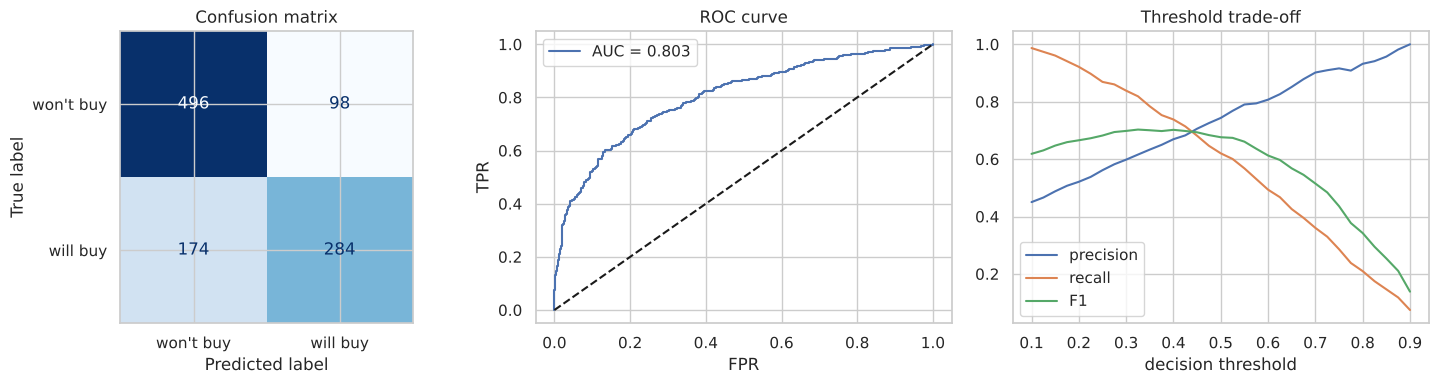

In [18]:
clf_models = B.classification_models()
logit = clone(clf_models['Logistic Regression']).fit(X_train, ytr_c)
p_log = logit.predict_proba(X_test)[:, 1]; yhat = (p_log >= .5).astype(int)
def clf_report(y_true, yhat, prob, name):
    return pd.Series({'Accuracy': accuracy_score(y_true, yhat), 'Precision': precision_score(y_true, yhat), 'Recall': recall_score(y_true, yhat),
                      'F1': f1_score(y_true, yhat), 'ROC-AUC': roc_auc_score(y_true, prob)}, name=name)
display(clf_report(yte_c, yhat, p_log, 'Logistic Regression').to_frame().T.round(3))
print(classification_report(yte_c, yhat, target_names=["won't buy", 'will buy']))
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ConfusionMatrixDisplay(confusion_matrix(yte_c, yhat), display_labels=["won't buy", 'will buy']).plot(ax=ax[0], cmap='Blues', colorbar=False); ax[0].set_title('Confusion matrix')
f, t, _ = roc_curve(yte_c, p_log); ax[1].plot(f, t, label=f'AUC = {roc_auc_score(yte_c, p_log):.3f}'); ax[1].plot([0, 1], [0, 1], 'k--'); ax[1].legend(); ax[1].set_title('ROC curve'); ax[1].set_xlabel('FPR'); ax[1].set_ylabel('TPR')
ths = np.linspace(.1, .9, 33)
ax[2].plot(ths, [precision_score(yte_c, p_log >= t_) for t_ in ths], label='precision'); ax[2].plot(ths, [recall_score(yte_c, p_log >= t_) for t_ in ths], label='recall')
ax[2].plot(ths, [f1_score(yte_c, p_log >= t_) for t_ in ths], label='F1'); ax[2].legend(); ax[2].set_xlabel('decision threshold'); ax[2].set_title('Threshold trade-off')
plt.tight_layout(); plt.show()

In [19]:
names = logit[:-1].get_feature_names_out()
coef = pd.Series(logit[-1].coef_[0], index=[n.split('__')[-1] for n in names]).sort_values()
odds = np.exp(coef).rename('odds ratio per +1 SD')
display(pd.concat([coef.rename('coefficient'), odds], axis=1).round(3).sort_values('coefficient'))

,coefficient,odds ratio per +1 SD
CountryGroup_EIRE,-0.487,0.614
AvgOrderValue,-0.477,0.621
TenureDays,-0.430,0.651
Spend_Last90,-0.156,0.855
Recency,-0.128,0.880
CountryGroup_Other,-0.097,0.908
ReturnRate,-0.048,0.953
CountryGroup_United Kingdom,-0.041,0.959
UniqueProducts,0.053,1.054
TotalQuantity,0.081,1.085


**Interpretation.** The largest positive effects come from `Monetary`, `Orders_Last90` and `Frequency` (odds ratios per +1 SD on the log scale above 1): customers who spend a lot and ordered recently are likelier to return. Several signs are negative (e.g. `AvgOrderValue`, `TenureDays`) *only after controlling for* Monetary and Frequency - a symptom of **multicollinearity** among the spend/volume features, so individual coefficients should not be over-read. Recency's effect is shared with `Orders_Last90` and `Spend_Last90`; the permutation importances in Experiments 8-9 give a more reliable ranking. Accuracy is ~74% against a 56% majority-class baseline; recall is lower than precision at the default 0.5 threshold, so if the business wants to catch more returning customers, a lower threshold (see the trade-off plot) is appropriate.

# Experiment 5 - KNN (from scratch) & Gaussian Naive Bayes
KNN is implemented with NumPy (vectorised squared-Euclidean distances, majority vote of the k nearest training points). It requires scaled features, so it is fed the preprocessed matrix. For cross-validation, **the preprocessor is re-fitted inside every fold** to avoid leakage.

In [20]:
class KNNScratch:
    """K-Nearest Neighbours classifier (binary) implemented with NumPy only."""
    def __init__(self, k=5): self.k = k
    def fit(self, X, y):
        self.X_ = np.asarray(X, float); self.y_ = np.asarray(y); return self
    def _sq_dist(self, A):                       # ||a-x||^2 = ||a||^2 - 2 a.x + ||x||^2 for all pairs
        return (A**2).sum(1)[:, None] - 2 * A @ self.X_.T + (self.X_**2).sum(1)[None, :]
    def predict_proba(self, A):
        D = self._sq_dist(np.asarray(A, float))
        nn = np.argpartition(D, self.k - 1, axis=1)[:, :self.k]   # indices of k smallest distances
        return self.y_[nn].mean(axis=1)                            # fraction of neighbours in class 1
    def predict(self, A): return (self.predict_proba(A) >= .5).astype(int)

from sklearn.neighbors import KNeighborsClassifier
knn_s = KNNScratch(k=15).fit(Z_train, ytr_c); knn_sk = KNeighborsClassifier(15).fit(Z_train, ytr_c)
agree = (knn_s.predict(Z_test) == knn_sk.predict(Z_test)).mean()
print(f'Scratch KNN vs sklearn KNN predictions agree on {agree:.1%} of test customers')

Scratch KNN vs sklearn KNN predictions agree on 100.0% of test customers


Best k by CV AUC: 41 -> {'AUC': 0.791, 'Accuracy': 0.731}


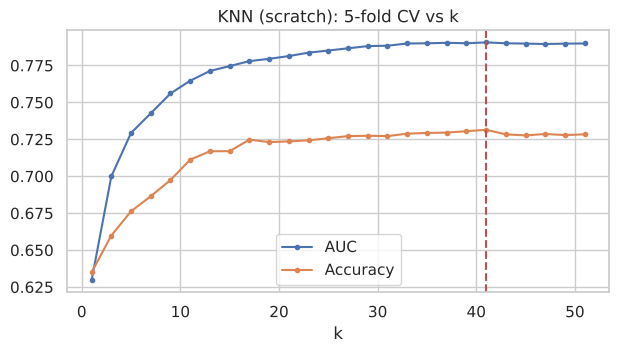

In [21]:
# choose k by 5-fold stratified CV on the training set (preprocessing re-fitted per fold)
skf = StratifiedKFold(5, shuffle=True, random_state=B.RANDOM_STATE)
ks = list(range(1, 52, 2)); cv_auc = {k: [] for k in ks}; cv_acc = {k: [] for k in ks}
for tr, va in skf.split(X_train, ytr_c):
    p = clone(pre).fit(X_train.iloc[tr]); Zt, Zv = p.transform(X_train.iloc[tr]), p.transform(X_train.iloc[va])
    for k in ks:
        m = KNNScratch(k).fit(Zt, ytr_c.iloc[tr]); pr = m.predict_proba(Zv)
        cv_auc[k].append(roc_auc_score(ytr_c.iloc[va], pr)); cv_acc[k].append(((pr >= .5) == ytr_c.iloc[va]).mean())
cv_k = pd.DataFrame({'AUC': {k: np.mean(v) for k, v in cv_auc.items()}, 'Accuracy': {k: np.mean(v) for k, v in cv_acc.items()}})
best_k = int(cv_k.AUC.idxmax()); print('Best k by CV AUC:', best_k, '->', cv_k.loc[best_k].round(3).to_dict())
cv_k.plot(figsize=(7, 3.4), marker='o', ms=3); plt.axvline(best_k, color='r', ls='--'); plt.xlabel('k'); plt.title('KNN (scratch): 5-fold CV vs k'); plt.show()

In [22]:
knn_best = KNNScratch(best_k).fit(Z_train, ytr_c); p_knn = knn_best.predict_proba(Z_test)
gnb = clone(clf_models['Gaussian Naive Bayes']).fit(X_train, ytr_c); p_gnb = gnb.predict_proba(X_test)[:, 1]
print('Gaussian NB class priors:', gnb[-1].class_prior_.round(3))
test_tab = pd.DataFrame([clf_report(yte_c, (p_knn >= .5).astype(int), p_knn, f'KNN scratch (k={best_k})'),
                         clf_report(yte_c, (p_gnb >= .5).astype(int), p_gnb, 'Gaussian Naive Bayes'),
                         clf_report(yte_c, yhat, p_log, 'Logistic Regression')])
display(test_tab.round(3))

# cross-validated comparison (same folds for all models)
cvr = {}
for nm, mdl in [('Gaussian Naive Bayes', clf_models['Gaussian Naive Bayes']), ('KNN sklearn (k=%d)' % best_k, None), ('Logistic Regression', clf_models['Logistic Regression'])]:
    if mdl is None: mdl = clone(clf_models['KNN (k=15)']).set_params(model__n_neighbors=best_k)
    r = cross_validate(mdl, X_train, ytr_c, cv=skf, scoring=['accuracy', 'f1', 'roc_auc']); cvr[nm] = {k.replace('test_', ''): v.mean() for k, v in r.items() if k.startswith('test_')}
cvr[f'KNN scratch (k={best_k})'] = {'accuracy': cv_k.loc[best_k, 'Accuracy'], 'roc_auc': cv_k.loc[best_k, 'AUC']}
display(pd.DataFrame(cvr).T[['accuracy', 'f1', 'roc_auc']].round(3).rename_axis('5-fold CV (train)'))

Gaussian NB class priors: [0.564 0.436]


,Accuracy,Precision,Recall,F1,ROC-AUC
KNN scratch (k=41),0.742,0.729,0.651,0.687,0.801
Gaussian Naive Bayes,0.721,0.722,0.583,0.645,0.778
Logistic Regression,0.741,0.743,0.620,0.676,0.803


,accuracy,f1,roc_auc
5-fold CV (train),,,
Gaussian Naive Bayes,0.674,0.609,0.769
KNN sklearn (k=41),0.731,0.680,0.791
Logistic Regression,0.723,0.661,0.790
KNN scratch (k=41),0.731,NaN,0.791


**Interpretation.** The from-scratch KNN reproduces scikit-learn's predictions (differences arise only from tie-breaking) and is competitive with logistic regression. Gaussian Naive Bayes is the weakest here: its assumption that features are conditionally independent and Gaussian is violated by our strongly correlated features (Monetary, Frequency, Quantity...), so probabilities are poorly calibrated even though it ranks reasonably well.

# Experiment 6 - K-Means Clustering (Customer Segmentation)
Features: **Recency, Frequency, Monetary** (RFM), log-transformed and standardised so that each contributes equally. No target is used.

k,2,3,4,5,6,7,8,9,10
Inertia,7669.464,5675.802,4468.230,3738.736,3296.234,2961.797,2705.243,2470.458,2276.467
Silhouette,0.456,0.356,0.376,0.332,0.327,0.299,0.281,0.288,0.279


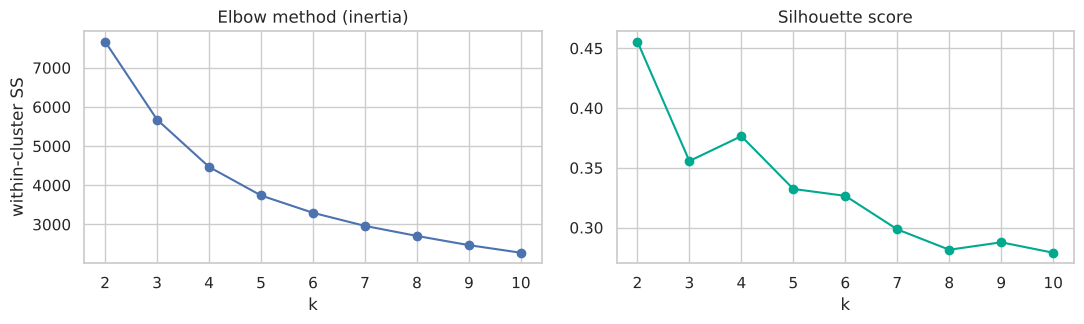

In [23]:
Z = B.cluster_features_matrix(cust)
rows = []
for k in range(2, 11):
    km = KMeans(k, n_init=10, random_state=B.RANDOM_STATE).fit(Z)
    rows.append({'k': k, 'Inertia': km.inertia_, 'Silhouette': silhouette_score(Z, km.labels_, sample_size=4000, random_state=B.RANDOM_STATE)})
ks_df = pd.DataFrame(rows).set_index('k'); display(ks_df.round(3).T)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ks_df.Inertia.plot(ax=ax[0], marker='o'); ax[0].set_title('Elbow method (inertia)'); ax[0].set_ylabel('within-cluster SS')
ks_df.Silhouette.plot(ax=ax[1], marker='o', color='#00A98F'); ax[1].set_title('Silhouette score')
plt.tight_layout(); plt.show()

The elbow is gentle (no sharp bend). **k = 2** has the highest silhouette but only separates active from dormant customers, which is too coarse for marketing. Among business-useful values (3-6) the silhouette is highest at **k = 4**, so we choose 4 segments - the same rule used by the training script.

In [24]:
K = int(ks_df.loc[3:6, 'Silhouette'].idxmax()); print('Chosen k =', K)
seg = B.fit_segmenter(cust, K)
cust['Segment'] = B.assign_segments(seg, cust); cust['SegmentName'] = cust.Segment.map(seg['names'])
prof = B.segment_profile(cust, cust.Segment.values); prof.insert(0, 'Name', [seg['names'][i] for i in prof.index])
display(prof.round(1))

Chosen k = 4


,Name,Customers,Recency,Frequency,Monetary,AvgOrderValue,TotalRevenue,% Customers,% Revenue,Repeat rate next 90d (%),Avg future spend (GBP)
Segment,,,,,,,,,,,
0,Champions,883,20.0,13.0,5065.4,364.4,9249493.5,16.8,67.6,84.4,2104.0
1,At-Risk Big Spenders,1560,167.0,5.0,1452.5,309.7,3184610.6,29.7,23.3,46.7,335.2
2,New & Promising,709,30.0,2.0,609.4,255.8,537397.0,13.5,3.9,55.0,376.1
3,Lapsed Low-Value,2104,327.0,1.0,293.4,206.4,719323.9,40.0,5.3,20.2,163.2


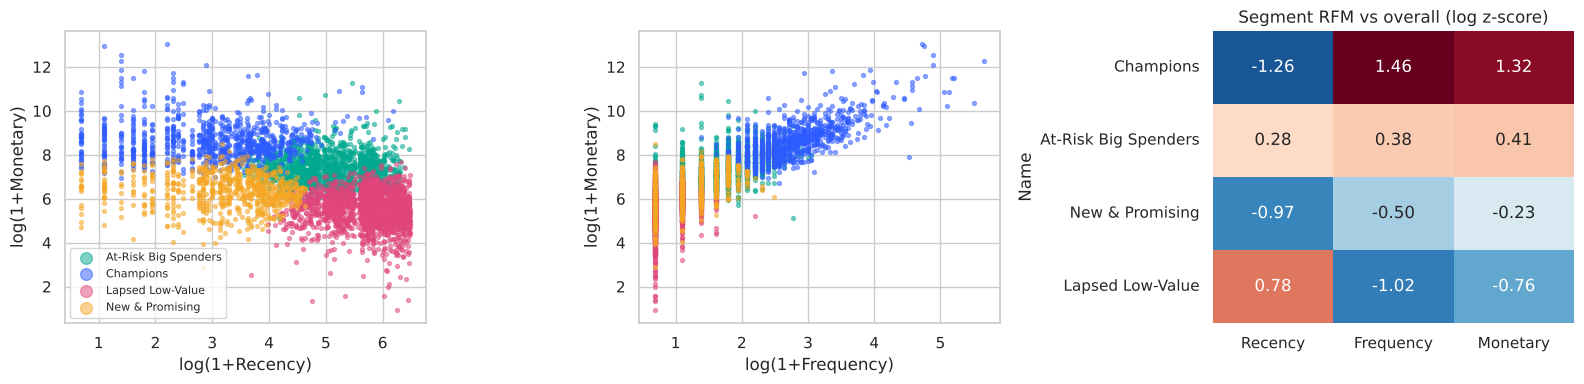

In [25]:
palette = dict(zip(prof.Name, ['#2E5BFF', '#00A98F', '#F5A623', '#E0457B', '#8B5CF6', '#64748B']))
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for nm, g in cust.groupby('SegmentName'):
    ax[0].scatter(np.log1p(g.Recency), np.log1p(g.Monetary), s=8, alpha=.5, label=nm, color=palette[nm])
    ax[1].scatter(np.log1p(g.Frequency), np.log1p(g.Monetary), s=8, alpha=.5, color=palette[nm])
ax[0].set_xlabel('log(1+Recency)'); ax[0].set_ylabel('log(1+Monetary)'); ax[0].legend(markerscale=3, fontsize=8); ax[1].set_xlabel('log(1+Frequency)'); ax[1].set_ylabel('log(1+Monetary)')
z = prof[B.CLUSTER_FEATURES].apply(np.log1p); z = (z - np.log1p(cust[B.CLUSTER_FEATURES]).mean()) / np.log1p(cust[B.CLUSTER_FEATURES]).std(); z.index = prof.Name
sns.heatmap(z, annot=True, fmt='.2f', cmap='RdBu_r', center=0, ax=ax[2], cbar=False); ax[2].set_title('Segment RFM vs overall (log z-score)')
plt.tight_layout(); plt.show()

In [26]:
for i, r in prof.iterrows():
    display(Markdown(f"**{r.Name}** - {int(r.Customers):,} customers ({r['% Customers']:.0f}%), {r['% Revenue']:.0f}% of revenue. Median last order {r.Recency:.0f} days ago, "
                     f"{r.Frequency:.0f} orders, GBP {r.Monetary:,.0f} lifetime; {r['Repeat rate next 90d (%)']:.0f}% bought again in the next 90 days. *Action:* {B.action_for(r.Name)}"))

**Champions** - 883 customers (17%), 68% of revenue. Median last order 20 days ago, 13 orders, GBP 5,065 lifetime; 84% bought again in the next 90 days. *Action:* Reward and retain: early access, loyalty perks, referral incentives. Protect margin - do not discount.

**At-Risk Big Spenders** - 1,560 customers (30%), 23% of revenue. Median last order 167 days ago, 5 orders, GBP 1,453 lifetime; 47% bought again in the next 90 days. *Action:* Win back fast: personalised outreach, 'we miss you' offer, reminders of favourite products.

**New & Promising** - 709 customers (13%), 4% of revenue. Median last order 30 days ago, 2 orders, GBP 609 lifetime; 55% bought again in the next 90 days. *Action:* Nurture: onboarding emails and a second-order incentive to build the habit.

**Lapsed Low-Value** - 2,104 customers (40%), 5% of revenue. Median last order 327 days ago, 1 orders, GBP 293 lifetime; 20% bought again in the next 90 days. *Action:* Low-cost reactivation only (email), otherwise deprioritise marketing spend.

# Experiment 7 - Gaussian Mixture Model (soft clustering) with PCA
A GMM models the data as a mixture of Gaussians and gives each customer a **probability of membership** in every cluster, rather than a hard label.

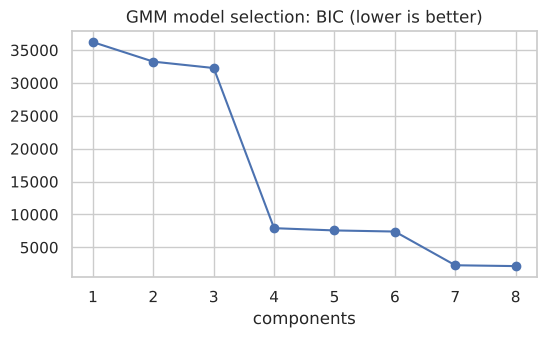

Lowest BIC at k = 8 - we use k = 4 for a like-for-like comparison with K-Means.


,CustomerID,P(comp 0),P(comp 1),P(comp 2),P(comp 3),Hard label
0,12346,0.000,0.999,0.001,0.0,1
1,12347,0.000,0.732,0.268,0.0,1
2,12348,0.000,0.065,0.935,0.0,2
3,12349,0.999,0.000,0.000,0.0,0
4,12350,0.000,0.000,0.000,1.0,3
5,12351,0.000,0.000,0.000,1.0,3
6,12352,0.000,0.077,0.923,0.0,2
7,12353,0.999,0.000,0.001,0.0,0


Mean max membership probability: 0.940; customers with max prob < 0.7 (ambiguous): 6.9%


In [27]:
from sklearn.mixture import GaussianMixture
from sklearn.decomposition import PCA
bic = {k: GaussianMixture(k, covariance_type='full', n_init=3, random_state=B.RANDOM_STATE).fit(Z).bic(Z) for k in range(1, 9)}
pd.Series(bic).plot(marker='o', figsize=(6, 3.2)); plt.title('GMM model selection: BIC (lower is better)'); plt.xlabel('components'); plt.show()
print('Lowest BIC at k =', min(bic, key=bic.get), '- we use k =', K, 'for a like-for-like comparison with K-Means.')
gmm = GaussianMixture(K, covariance_type='full', n_init=5, random_state=B.RANDOM_STATE).fit(Z)
proba = gmm.predict_proba(Z); g_raw = proba.argmax(1)
cust['GMM'] = B.order_labels_by_spend(g_raw, cust)
order_map = {int(r): int(n) for r, n in zip(g_raw, cust.GMM)}
P = pd.DataFrame(proba, columns=[f'P(comp {j})' for j in range(K)]); P.insert(0, 'CustomerID', cust.CustomerID); P['Hard label'] = g_raw
display(P.head(8).round(3))
mx = proba.max(1)
print(f'Mean max membership probability: {mx.mean():.3f}; customers with max prob < 0.7 (ambiguous): {(mx < .7).mean():.1%}')

PCA explained variance: [0.762 0.188] -> total 0.95


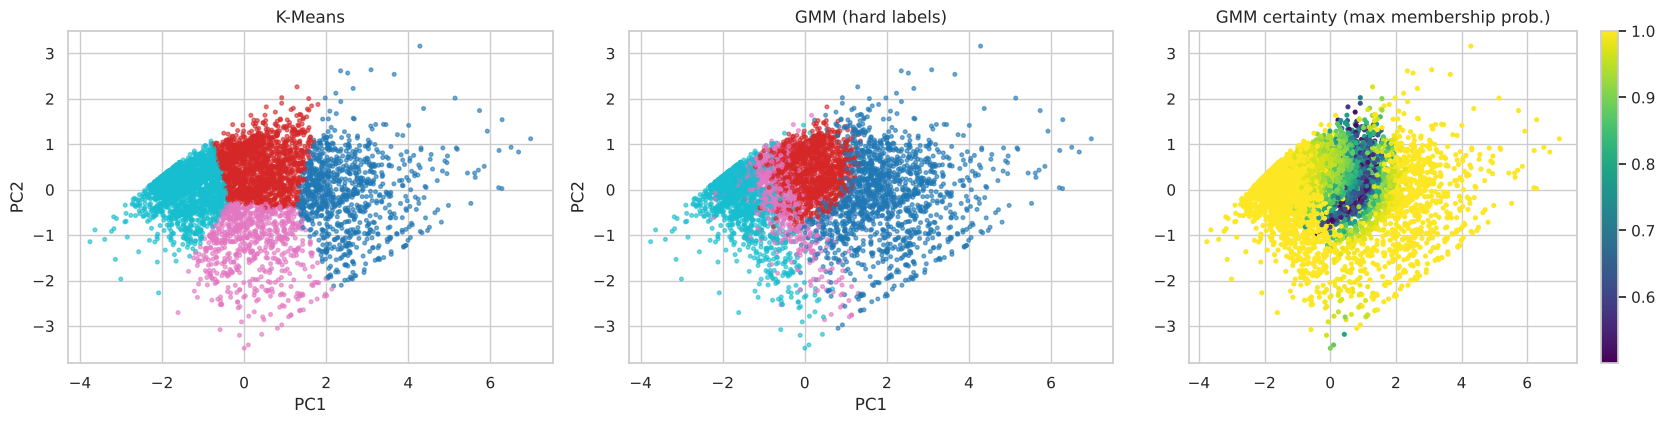

In [28]:
pca = PCA(2, random_state=B.RANDOM_STATE).fit(Z); P2 = pca.transform(Z)
print('PCA explained variance:', pca.explained_variance_ratio_.round(3), '-> total', pca.explained_variance_ratio_.sum().round(3))
fig, ax = plt.subplots(1, 3, figsize=(17, 4.4))
for a, lab, t in [(ax[0], cust.Segment, 'K-Means'), (ax[1], cust.GMM, 'GMM (hard labels)')]:
    sc_ = a.scatter(P2[:, 0], P2[:, 1], c=lab, cmap='tab10', s=7, alpha=.6); a.set_title(t); a.set_xlabel('PC1'); a.set_ylabel('PC2')
sc_ = ax[2].scatter(P2[:, 0], P2[:, 1], c=mx, cmap='viridis', s=7); ax[2].set_title('GMM certainty (max membership prob.)'); plt.colorbar(sc_, ax=ax[2])
plt.tight_layout(); plt.show()

In [29]:
ari = adjusted_rand_score(cust.Segment, cust.GMM); nmi = normalized_mutual_info_score(cust.Segment, cust.GMM)
print(f'K-Means vs GMM: Adjusted Rand Index = {ari:.3f}, NMI = {nmi:.3f}')
print(f"Silhouette  K-Means: {silhouette_score(Z, cust.Segment, sample_size=4000, random_state=0):.3f} | GMM: {silhouette_score(Z, cust.GMM, sample_size=4000, random_state=0):.3f}")
display(pd.crosstab(cust.Segment.map(seg['names']), cust.GMM, rownames=['K-Means segment'], colnames=['GMM cluster (0 = highest spend)']))

K-Means vs GMM: Adjusted Rand Index = 0.459, NMI = 0.482


Silhouette  K-Means: 0.377 | GMM: 0.194


GMM cluster (0 = highest spend),0,1,2,3
K-Means segment,,,,
At-Risk Big Spenders,249,1174,121,16
Champions,883,0,0,0
Lapsed Low-Value,0,144,570,1390
New & Promising,267,75,198,169


**Interpretation.** K-Means and GMM agree on the broad structure (the cross-tab is concentrated along the diagonal) on the extremes (all *Champions* land in GMM cluster 0) but only partly in the middle (Adjusted Rand Index about 0.46): RFM data forms a continuous cloud rather than separated blobs, so the two methods draw the middle boundaries differently. About 7% of customers have ambiguous GMM membership (max probability < 0.7). GMM's soft probabilities identify exactly these **borderline customers**, which K-Means' hard labels hide, and its full covariance lets clusters be elongated instead of spherical. K-Means yields the higher silhouette (it optimises compactness) and simpler, more stable segments, so it is used for the dashboard's default segmentation; the app also lets you switch to GMM.

# Experiment 8 - Ensemble Learning: Decision Tree, Bagging, Random Forest
All models use the same preprocessing (median imputation + one-hot, no scaling needed for trees), the same train/test split and the same 5-fold stratified CV, so comparisons are fair.

In [30]:
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier, GradientBoostingClassifier
def tree_pipe(est): return Pipeline([('prep', B.make_preprocessor(scale=False, log=False)), ('model', est)])
rs_ = B.RANDOM_STATE
ens = {'Decision Tree (unpruned)': tree_pipe(DecisionTreeClassifier(random_state=rs_)),
       'Decision Tree (depth 5)': tree_pipe(DecisionTreeClassifier(max_depth=5, min_samples_leaf=20, random_state=rs_)),
       'Bagging (100 trees)': tree_pipe(BaggingClassifier(DecisionTreeClassifier(min_samples_leaf=5), n_estimators=100, n_jobs=-1, random_state=rs_)),
       'Random Forest (300 trees)': tree_pipe(RandomForestClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=rs_)),
       'Gradient Boosting': tree_pipe(GradientBoostingClassifier(n_estimators=150, max_depth=3, learning_rate=.05, random_state=rs_))}
rows, fitted = [], {}
for nm, m in ens.items():
    cv = cross_validate(m, X_train, ytr_c, cv=skf, scoring=['accuracy', 'roc_auc'], return_train_score=True)
    m.fit(X_train, ytr_c); pr = m.predict_proba(X_test)[:, 1]; fitted[nm] = (m, pr)
    rows.append({'Model': nm, 'Train AUC': cv['train_roc_auc'].mean(), 'CV AUC': cv['test_roc_auc'].mean(), 'CV AUC std': cv['test_roc_auc'].std(),
                 'CV Acc': cv['test_accuracy'].mean(), 'Test Acc': accuracy_score(yte_c, pr >= .5), 'Test F1': f1_score(yte_c, pr >= .5), 'Test AUC': roc_auc_score(yte_c, pr)})
ens_tab = pd.DataFrame(rows).set_index('Model'); display(ens_tab.round(3))

,Train AUC,CV AUC,CV AUC std,CV Acc,Test Acc,Test F1,Test AUC
Model,,,,,,,
Decision Tree (unpruned),1.000,0.637,0.018,0.645,0.660,0.613,0.655
Decision Tree (depth 5),0.819,0.771,0.010,0.717,0.738,0.685,0.810
Bagging (100 trees),0.978,0.780,0.010,0.717,0.747,0.689,0.808
Random Forest (300 trees),0.961,0.788,0.013,0.722,0.747,0.681,0.813
Gradient Boosting,0.856,0.795,0.010,0.725,0.746,0.678,0.819


The unpruned tree has a train AUC of 1.0 but a much lower CV AUC: it **memorises** the training data (high variance). Pruning (depth 5) removes most of that over-fitting; Bagging averages many deep trees and the Random Forest additionally decorrelates them by sampling features at each split, giving the best CV AUC among the parallel ensembles (0.788 vs 0.780 for bagging and 0.771 for the pruned tree). Boosting reduces bias sequentially and is best overall on CV AUC, though the differences between the good models (~0.01 AUC) are about one standard deviation of the CV estimate.

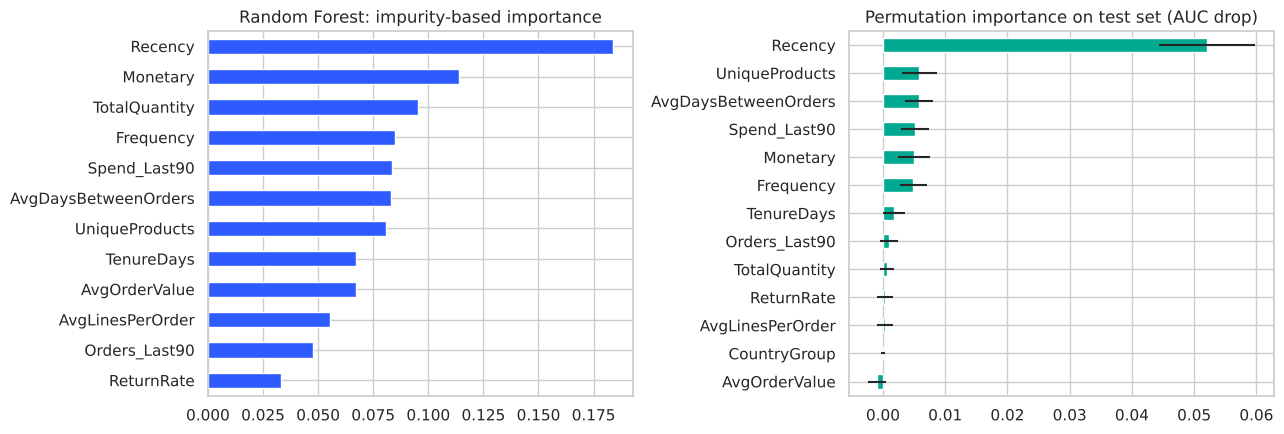

Random Forest out-of-bag accuracy (free validation estimate): 0.725


In [31]:
rf = fitted['Random Forest (300 trees)'][0]
fn = [n.split('__')[-1] for n in rf[:-1].get_feature_names_out()]
imp = pd.Series(rf[-1].feature_importances_, index=fn).sort_values()
from sklearn.inspection import permutation_importance
pi = permutation_importance(rf, X_test, yte_c, n_repeats=10, scoring='roc_auc', random_state=rs_, n_jobs=1)
pim = pd.Series(pi.importances_mean, index=B.FEATURES).sort_values()
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
imp.tail(12).plot.barh(ax=ax[0], color='#2E5BFF'); ax[0].set_title('Random Forest: impurity-based importance')
pim.plot.barh(ax=ax[1], xerr=pi.importances_std[np.argsort(pi.importances_mean)], color='#00A98F'); ax[1].set_title('Permutation importance on test set (AUC drop)')
plt.tight_layout(); plt.show()
oob = RandomForestClassifier(300, min_samples_leaf=5, oob_score=True, random_state=rs_, n_jobs=-1).fit(B.make_preprocessor(False, False).fit_transform(X_train), ytr_c)
print(f'Random Forest out-of-bag accuracy (free validation estimate): {oob.oob_score_:.3f}')

Both importance methods rank **Recency** far above everything else (the permutation drop for Recency is roughly 5-10x that of any other feature), even though the logistic coefficients spread its effect over correlated features. Impurity importance tends to favour continuous, high-cardinality features; permutation importance on held-out data is the more trustworthy view.

# Experiment 9 - Cross-Validation & Hyper-parameter Optimisation
### 9.1 K-Fold vs Stratified K-Fold

In [32]:
rf_pipe = ens['Random Forest (300 trees)']
kf5 = KFold(5, shuffle=True, random_state=rs_)
res = {}
for nm, cv in [('KFold', kf5), ('StratifiedKFold', skf)]:
    sc_ = cross_val_score(rf_pipe, X_train, ytr_c, cv=cv, scoring='roc_auc'); res[nm] = sc_
    print(f'{nm:16s} AUC per fold: {sc_.round(3)}  mean={sc_.mean():.4f} std={sc_.std():.4f}')
pos = {nm: [ytr_c.iloc[va].mean() for _, va in cv.split(X_train, ytr_c)] for nm, cv in [('KFold', kf5), ('StratifiedKFold', skf)]}
print('\nPositive-class rate in each validation fold:'); display(pd.DataFrame(pos).round(4).T)

KFold            AUC per fold: [0.805 0.788 0.791 0.791 0.788]  mean=0.7928 std=0.0062


StratifiedKFold  AUC per fold: [0.788 0.807 0.797 0.776 0.773]  mean=0.7884 std=0.0128

Positive-class rate in each validation fold:


,0,1,2,3,4
KFold,0.4447,0.4102,0.4257,0.4447,0.4524
StratifiedKFold,0.4364,0.4352,0.4352,0.4352,0.4357


Our classes are fairly balanced (~44% positive), so both give similar scores, but stratification keeps the class proportion almost identical in every fold and is the safer default for classification. **Plain K-Fold is used for regression** (a continuous target cannot be stratified).

### 9.2 GridSearchCV (exhaustive) and RandomizedSearchCV (sampled)

In [33]:
t0 = time.time()
grid_lr = GridSearchCV(clone(clf_models['Logistic Regression']), {'model__C': [0.01, 0.1, 1, 10, 100], 'model__class_weight': [None, 'balanced']},
                       cv=skf, scoring='roc_auc', n_jobs=1).fit(X_train, ytr_c)
print(f'GridSearch Logistic  ({time.time()-t0:.0f}s): best CV AUC {grid_lr.best_score_:.4f}', grid_lr.best_params_)
t0 = time.time()
grid_rf = GridSearchCV(clone(ens['Random Forest (300 trees)']).set_params(model__n_estimators=200),
                       {'model__max_depth': [4, 8, None], 'model__min_samples_leaf': [5, 20], 'model__max_features': ['sqrt', 0.5]},
                       cv=3, scoring='roc_auc', n_jobs=1).fit(X_train, ytr_c)
print(f'GridSearch RandomForest ({time.time()-t0:.0f}s): best CV AUC {grid_rf.best_score_:.4f}', grid_rf.best_params_)
t0 = time.time()
rand_gb = RandomizedSearchCV(clone(ens['Gradient Boosting']),
                             {'model__n_estimators': [100, 150, 250, 400], 'model__max_depth': [2, 3, 4, 5], 'model__learning_rate': [0.02, 0.05, 0.1, 0.2],
                              'model__subsample': [0.6, 0.8, 1.0], 'model__min_samples_leaf': [5, 10, 30]},
                             n_iter=12, cv=3, scoring='roc_auc', random_state=rs_, n_jobs=1).fit(X_train, ytr_c)
print(f'RandomizedSearch GradientBoosting ({time.time()-t0:.0f}s): best CV AUC {rand_gb.best_score_:.4f}', rand_gb.best_params_)
cvdf = pd.DataFrame(grid_rf.cv_results_)[['param_model__max_depth', 'param_model__min_samples_leaf', 'param_model__max_features', 'mean_test_score']].sort_values('mean_test_score', ascending=False)
display(cvdf.head(6).round(4))

GridSearch Logistic  (2s): best CV AUC 0.7903 {'model__C': 0.1, 'model__class_weight': None}


GridSearch RandomForest (23s): best CV AUC 0.7969 {'model__max_depth': 4, 'model__max_features': 0.5, 'model__min_samples_leaf': 5}


RandomizedSearch GradientBoosting (64s): best CV AUC 0.7945 {'model__subsample': 1.0, 'model__n_estimators': 150, 'model__min_samples_leaf': 30, 'model__max_depth': 2, 'model__learning_rate': 0.02}


,param_model__max_depth,param_model__min_samples_leaf,param_model__max_features,mean_test_score
2,4,5,0.5,0.7969
3,4,20,0.5,0.7967
5,8,20,sqrt,0.7963
9,None,20,sqrt,0.7961
7,8,20,0.5,0.7953
0,4,5,sqrt,0.7952


Grid search tries **every** combination (feasible for small grids: 10 combos for logistic regression, 12 for the forest). Randomised search samples a fixed budget (12 of 576 combinations) from the much larger gradient-boosting space; it finds near-optimal settings at a fraction of the cost.

### 9.3 Tuned models on the held-out test set

,Accuracy,Precision,Recall,F1,ROC-AUC
Logistic (baseline),0.741,0.743,0.620,0.676,0.803
Logistic (grid),0.745,0.751,0.620,0.679,0.803
Random Forest (baseline),0.747,0.755,0.620,0.681,0.813
Random Forest (grid),0.756,0.771,0.624,0.690,0.817
Gradient Boosting (baseline),0.746,0.757,0.614,0.678,0.819
Gradient Boosting (random),0.740,0.757,0.592,0.664,0.815


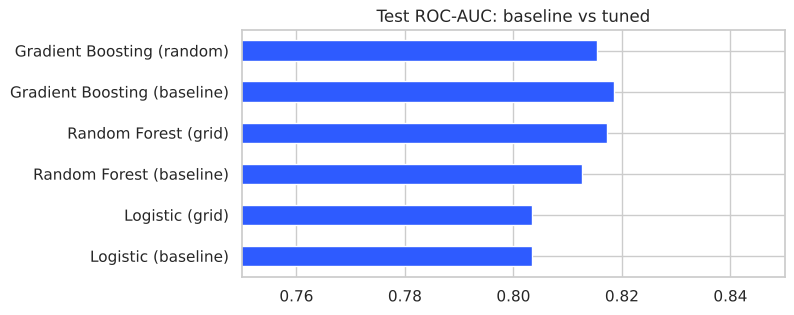

In [34]:
final = {'Logistic (baseline)': logit, 'Logistic (grid)': grid_lr.best_estimator_, 'Random Forest (baseline)': fitted['Random Forest (300 trees)'][0],
         'Random Forest (grid)': grid_rf.best_estimator_, 'Gradient Boosting (baseline)': fitted['Gradient Boosting'][0], 'Gradient Boosting (random)': rand_gb.best_estimator_}
rows = []
for nm, m in final.items():
    pr = m.predict_proba(X_test)[:, 1]; rows.append(clf_report(yte_c, (pr >= .5).astype(int), pr, nm))
final_tab = pd.DataFrame(rows); display(final_tab.round(3))
final_tab['ROC-AUC'].plot.barh(figsize=(7, 3.2), color='#2E5BFF'); plt.xlim(.75, .85); plt.title('Test ROC-AUC: baseline vs tuned'); plt.show()

### 9.4 Tuning the regression model (RandomizedSearchCV, 3-fold)
Spend is heavy-tailed, so a handful of customers dominate any GBP-scale error and make the search noisy. The model is trained on log(1 + spend), so we tune on the **same scale**: a custom scorer computes RMSE between log(1+actual) and log(1+predicted).

In [35]:
from sklearn.metrics import make_scorer
def rmse_log(y_true, y_pred): return np.sqrt(mean_squared_error(np.log1p(y_true), np.log1p(np.clip(y_pred, 0, None))))
log_scorer = make_scorer(rmse_log, greater_is_better=False)
reg_base = clone(B.regression_models()['Hist Gradient Boosting'])
rs_reg = RandomizedSearchCV(reg_base, {'regressor__model__max_depth': [2, 3, 4, 6], 'regressor__model__learning_rate': [0.02, 0.05, 0.1],
                                       'regressor__model__max_iter': [150, 250, 400], 'regressor__model__min_samples_leaf': [10, 20, 50],
                                       'regressor__model__l2_regularization': [0, 1, 10]},
                            n_iter=10, cv=3, scoring=log_scorer, random_state=rs_, n_jobs=1).fit(X_train, ytr_r)
print('Best params:', rs_reg.best_params_, '| best CV RMSE (log scale):', round(-rs_reg.best_score_, 4))
rep = pd.DataFrame([reg_report(yte_r, np.clip(reg_base.fit(X_train, ytr_r).predict(X_test), 0, None), 'HistGB baseline'),
                    reg_report(yte_r, np.clip(rs_reg.best_estimator_.predict(X_test), 0, None), 'HistGB tuned')]); display(rep.round(3))

Best params: {'regressor__model__min_samples_leaf': 10, 'regressor__model__max_iter': 150, 'regressor__model__max_depth': 3, 'regressor__model__learning_rate': 0.02, 'regressor__model__l2_regularization': 0} | best CV RMSE (log scale): 2.6107


,MAE (GBP),MSE,RMSE (GBP),R2 (GBP),R2 (log scale)
HistGB baseline,327.067,976212.944,988.035,0.616,0.376
HistGB tuned,372.238,1812432.346,1346.266,0.287,0.372


**Result.** Tuning did **not** improve on the default Hist Gradient Boosting settings: log-scale R² is essentially unchanged (0.376 vs 0.372) and GBP error is worse, because the search prefers a smaller learning rate and fewer iterations, which shrinks predictions for the few very large accounts. With ~4,200 training customers and a noisy, heavy-tailed target, the CV estimate cannot separate these settings. The dashboard therefore keeps the default configuration - a useful reminder that hyper-parameter search is not guaranteed to help and must be judged on held-out data.

### 9.5 Feature importance of the final models

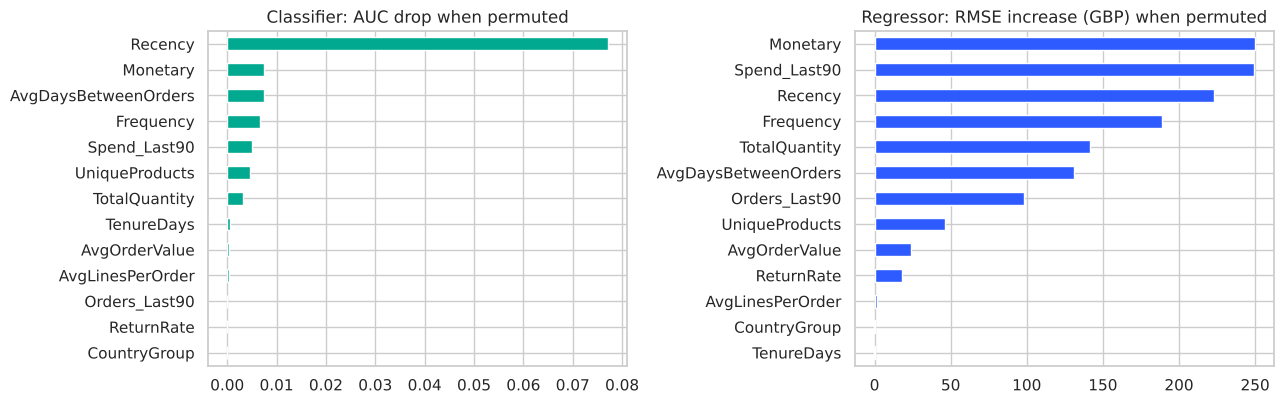

In [36]:
best_clf = final['Random Forest (grid)'] if final_tab.loc['Random Forest (grid)', 'ROC-AUC'] >= final_tab.loc['Gradient Boosting (random)', 'ROC-AUC'] else final['Gradient Boosting (random)']
pi_c = permutation_importance(best_clf, X_test, yte_c, n_repeats=8, scoring='roc_auc', random_state=rs_, n_jobs=1)
pi_r = permutation_importance(rs_reg.best_estimator_, X_test, yte_r, n_repeats=5, scoring='neg_root_mean_squared_error', random_state=rs_, n_jobs=1)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
pd.Series(pi_c.importances_mean, index=B.FEATURES).sort_values().plot.barh(ax=ax[0], color='#00A98F'); ax[0].set_title('Classifier: AUC drop when permuted')
pd.Series(pi_r.importances_mean, index=B.FEATURES).sort_values().plot.barh(ax=ax[1], color='#2E5BFF'); ax[1].set_title('Regressor: RMSE increase (GBP) when permuted')
plt.tight_layout(); plt.show()

# Consistency check with the Streamlit app
The app loads the models saved by `backend.py` (same data prep, same split, same seed). Evaluating those saved artifacts here on this notebook's test set should reproduce the dashboard's numbers.

In [37]:
if B.artifacts_exist():
    art = B.load_artifacts(); sm = art['models']['models']
    pr = sm['classification'].predict_proba(X_test)[:, 1]
    saved = art['results']['classification']['table'].loc[art['models']['names']['classification']]
    print(f"Saved classifier ({art['models']['names']['classification']}): ROC-AUC here = {roc_auc_score(yte_c, pr):.4f} | dashboard table = {saved['ROC-AUC']:.4f}")
    rp = np.clip(sm['regression'].predict(X_test), 0, None)
    savedr = art['results']['regression']['table'].loc[art['models']['names']['regression']]
    print(f"Saved regressor ({art['models']['names']['regression']}): RMSE here = {np.sqrt(mean_squared_error(yte_r, rp)):.1f} | dashboard table = {savedr['RMSE']:.1f}")
    seg_saved = art['segmenter']; print('Saved segmenter k =', seg_saved['k'], '| notebook k =', K, '| same names:', seg_saved['names'] == seg['names'])
    print('Same customer table:', np.allclose(art['customers']['Monetary'].values, cust['Monetary'].values))
else:
    print('No saved artifacts yet - run `python backend.py` to create them.')

Saved classifier (Random Forest (tuned)): ROC-AUC here = 0.8172 | dashboard table = 0.8172
Saved regressor (Hist Gradient Boosting): RMSE here = 988.0 | dashboard table = 988.0
Saved segmenter k = 4 | notebook k = 4 | same names: True
Same customer table: True


# Conclusions

In [38]:
r = ens_tab; best = r['Test AUC'].idxmax()
top = prof.sort_values('% Revenue', ascending=False).iloc[0]
display(Markdown(f'''
**Data & design.** {len(raw):,} raw invoice lines were reduced to {len(sales):,} valid sales lines and **{len(cust):,} customers** with features at {cutoff.date()} and targets in the following {B.HORIZON_DAYS} days (no leakage). {cust.Active.mean():.0%} of customers bought again.

**Segmentation.** K-Means (k = {K}, silhouette {ks_df.loc[K, 'Silhouette']:.2f}) finds {K} RFM segments. *{top.Name}* is {top['% Customers']:.0f}% of customers but {top['% Revenue']:.0f}% of revenue. GMM agrees broadly (ARI {ari:.2f}) and flags {(mx < .7).mean():.0%} of customers as borderline.

**Classification.** Recency is by far the most informative signal (by permutation importance). Test ROC-AUC: logistic {roc_auc_score(yte_c, p_log):.3f}, KNN {roc_auc_score(yte_c, p_knn):.3f}, Naive Bayes {roc_auc_score(yte_c, p_gnb):.3f}, best ensemble ({best}) {r.loc[best, 'Test AUC']:.3f}; tuning added little because the problem is dominated by one feature (accuracy ceiling ~75%).

**Regression.** A single-feature linear model explains part of the log-scale variance; tree ensembles are clearly better in GBP (HistGB RMSE {np.sqrt(mean_squared_error(yte_r, np.clip(reg_base.predict(X_test), 0, None))):,.0f} vs {np.sqrt(mean_squared_error(yte_r, pred_simple)):,.0f} for the simple linear model). Individual-customer spend remains hard to predict, so use predictions for ranking and totals.

**Limitations.** One snapshot date (no rolling back-test), customers without an ID (~22% of lines) are excluded, and no product-category/marketing features are used.
'''))


**Data & design.** 1,067,371 raw invoice lines were reduced to 776,577 valid sales lines and **5,256 customers** with features at 2011-09-11 and targets in the following 90 days (no leakage). 44% of customers bought again.

**Segmentation.** K-Means (k = 4, silhouette 0.38) finds 4 RFM segments. *Champions* is 17% of customers but 68% of revenue. GMM agrees broadly (ARI 0.46) and flags 7% of customers as borderline.

**Classification.** Recency is by far the most informative signal (by permutation importance). Test ROC-AUC: logistic 0.803, KNN 0.801, Naive Bayes 0.778, best ensemble (Gradient Boosting) 0.819; tuning added little because the problem is dominated by one feature (accuracy ceiling ~75%).

**Regression.** A single-feature linear model explains part of the log-scale variance; tree ensembles are clearly better in GBP (HistGB RMSE 988 vs 1,473 for the simple linear model). Individual-customer spend remains hard to predict, so use predictions for ranking and totals.

**Limitations.** One snapshot date (no rolling back-test), customers without an ID (~22% of lines) are excluded, and no product-category/marketing features are used.
